# Tópicos de Big Data — Segundo examen parcial
## Examen práctico · Versión A

**Tiempo máximo:** 90 minutos  
**Calificación de este examen práctico:** 100 puntos (escala de 0 a 100)  
**Nombre:** Pablo Eduardo Magaña Gutierrez 
**Grupo:** 511  **Fecha:** 26/10/2026

### Situación de análisis
Se dispone de un conjunto de datos de viajes de taxi de Nueva York. Tu tarea consiste en aplicar **K-Means** para responder la siguiente pregunta:

> **¿Qué tipos de viajes pagados en efectivo se pueden identificar según la distancia recorrida y la duración del viaje?**

Trabajarás únicamente con los viajes cuyo tipo de pago sea **`Cash`** y utilizarás las variables **`trip_distance`** y **`trip_duration`**.

### Reglas de entrega
- Escribe tu propio código en las celdas vacías que aparecen después de cada instrucción.
- Ejecuta todas las celdas en orden y conserva las tablas y gráficas resultantes.
- Utiliza **Python, Pandas, NumPy, Matplotlib y scikit-learn**.
- No es necesario utilizar técnicas distintas de las estudiadas en clase.
- Guarda el archivo como **`Examen_A_Apellido_Nombre.ipynb`** y entrégalo con sus resultados visibles.
- El número de clústeres **no está predeterminado**: deberás seleccionarlo y justificarlo con evidencia.

**Ubicación obligatoria del dataset:** dentro de la carpeta de tu examen, guarda el archivo `nyc_taxi_examen.csv` en la subcarpeta `data/raw/`. La ruta relativa desde este notebook será **`data/raw/nyc_taxi_examen.csv`** (no es una ruta absoluta del sistema).

**Estructura de carpetas:**
```text
Examen_A/
└── notebooks/
    └── Examen_A_Apellido_Nombre.ipynb
└── data/
    └── raw/
        └── nyc_taxi_examen.csv
```

## 1. Carga y exploración de datos — 7 puntos · 10 minutos

**Escribe el código necesario para:**
1. Importar las bibliotecas que utilizarás.
2. Cargar el archivo CSV **`../data/raw/nyc_taxi_examen.csv`** en un DataFrame llamado `df`. La ruta es relativa a la carpeta donde está este notebook.
3. Mostrar las **primeras cinco filas**, las **dimensiones**, los **nombres de las columnas** y los **tipos de datos**.
4. Mostrar un resumen estadístico de las columnas numéricas.
5. Comprobar qué valores existen en la columna `payment_type`.

**Evidencia:** deja visibles los resultados de exploración.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
df = pd.read_csv("../data/raw/nyc_taxi_examen.csv")
display(df.head(5))
print(df.info())

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
0,1,2026-08-01 00:03:04,2026-08-01 00:07:51,1.0,0.60,1.0,140.0,262.0,1.0,6.5,3.5,0.5,2.30,0.00,1.0,13.80,2.5,0.0,0.00,4.783333
1,1,2026-08-01 00:38:45,2026-08-01 00:44:02,1.0,0.70,1.0,140.0,262.0,1.0,6.5,3.5,0.5,3.45,0.00,1.0,14.95,2.5,0.0,0.00,5.283333
2,1,NaN,2026-08-01 01:01:07,100.0,1.10,1.0,140.0,263.0,1.0,7.9,3.5,0.5,2.60,0.00,1.0,15.50,2.5,0.0,0.00,6.266667
3,1,2026-08-01 00:27:35,2026-08-01 00:54:27,1.0,5.24,1.0,164.0,80.0,1.0,29.6,1.0,0.5,8.56,7.46,1.0,51.37,2.5,0.0,0.75,26.866667
4,2,2026-08-01 00:39:08,2026-08-01 01:00:23,1.0,3.57,1.0,148.0,141.0,1.0,20.5,NaN,0.5,5.25,0.00,1.0,31.50,2.5,0.0,0.75,21.250000


<class 'pandas.DataFrame'>
RangeIndex: 2427612 entries, 0 to 2427611
Data columns (total 20 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   VendorID               int64  
 1   tpep_pickup_datetime   str    
 2   tpep_dropoff_datetime  str    
 3   passenger_count        float64
 4   trip_distance          float64
 5   RatecodeID             float64
 6   PULocationID           float64
 7   DOLocationID           float64
 8   payment_type           float64
 9   fare_amount            float64
 10  extra                  float64
 11  mta_tax                float64
 12  tip_amount             float64
 13  tolls_amount           float64
 14  improvement_surcharge  float64
 15  total_amount           float64
 16  congestion_surcharge   float64
 17  Airport_fee            float64
 18  cbd_congestion_fee     float64
 19  trip_duration          float64
dtypes: float64(17), int64(1), str(2)
memory usage: 370.4 MB
None


## 2. Revisión y limpieza de datos — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Crear una copia de los datos originales llamada `df_limpio`.
2. Contar los **valores nulos por columna** y los **registros duplicados** antes de la limpieza.
3. Eliminar registros duplicados y filas que contengan valores nulos.
4. Conservar únicamente los registros que cumplan **todas** estas condiciones:
   - `trip_distance > 0`
   - `passenger_count > 0` y `passenger_count < 100`
   - `fare_amount > 0` y `fare_amount < 10000`
   - `trip_duration > 0`
5. Mostrar cuántos registros quedan después de limpiar.

**Importante:** no elimines registros por valores atípicos utilizando percentiles ni otros métodos adicionales. Si el archivo ya fue depurado, verifica igualmente estas condiciones.

**Evidencia:** muestra los conteos y las dimensiones antes y después de limpiar.

In [15]:
df_limpio = df.copy()

print("Valores nulos y registros duplicados antes de la limpieza: ", df_limpio.shape)

print("Valores nulos por columna: \n", df_limpio.isnull().sum())
print("Registros duplicados: ", df_limpio.duplicated().sum())

print("Eliminando registros duplicados y valores nulos ")
df_limpio = df_limpio.drop_duplicates()
df_limpio = df_limpio.dropna()

condiciones = (
    (df_limpio["trip_distance"] > 0) &
    (df_limpio["passenger_count"] > 0) &
    (df_limpio["passenger_count"] < 100) &
    (df_limpio["fare_amount"] > 0) &
    (df_limpio["fare_amount"] < 10000) &
    (df_limpio["trip_duration"] > 0)
)

df_limpio = df_limpio.loc[condiciones].copy()

# Evidencia después de limpiar
print("DESPUÉS DE LIMPIAR")
print("Dimensiones:", df_limpio.shape)
print("Registros restantes:", len(df_limpio))
print("Valores nulos restantes:", df_limpio.isnull().sum().sum())
print("Registros duplicados restantes:", df_limpio.duplicated().sum())

Valores nulos y registros duplicados antes de la limpieza:  (2427612, 20)
Valores nulos por columna: 
 VendorID                     0
tpep_pickup_datetime     12126
tpep_dropoff_datetime    12127
passenger_count          12123
trip_distance            12142
RatecodeID               12138
PULocationID             12125
DOLocationID             12137
payment_type             12125
fare_amount              12124
extra                    12125
mta_tax                  12150
tip_amount               12153
tolls_amount             12147
improvement_surcharge    12131
total_amount             12128
congestion_surcharge     12155
Airport_fee              12131
cbd_congestion_fee       12150
trip_duration            12137
dtype: int64
Registros duplicados:  11961
Eliminando registros duplicados y valores nulos 
DESPUÉS DE LIMPIAR
Dimensiones: (2096600, 20)
Registros restantes: 2096600
Valores nulos restantes: 0
Registros duplicados restantes: 0


## 3. Filtrado y selección de variables — 7 puntos · 5 minutos

**Escribe el código necesario para:**
1. Filtrar los registros de `df_limpio` donde `payment_type` sea exactamente **`Cash`**. Guarda el resultado en `df_cash`.
2. Seleccionar únicamente **`trip_distance`** y **`trip_duration`** para el agrupamiento. Guarda esas dos columnas en un DataFrame llamado `X`.
3. Mostrar la cantidad de viajes filtrados y las estadísticas descriptivas de `X`.

**Recuerda:** utiliza **únicamente estas dos variables** para entrenar K-Means.

**Evidencia:** cantidad de registros y tabla descriptiva.

In [24]:
df_cash = df_limpio[df_limpio["payment_type"] == 2].copy()
X = df_cash[["trip_distance", "trip_duration"]].copy()
print("Dimensiones de df_cash:", len(df_cash))
print("Dimensiones de X:", X.describe())




Dimensiones de df_cash: 282085
Dimensiones de X:        trip_distance  trip_duration
count  282085.000000  282085.000000
mean        3.842165      17.507243
std         6.214391      40.684025
min         0.010000       0.033333
25%         0.920000       7.400000
50%         1.700000      12.416667
75%         4.370000      20.883333
max      1686.490000    8373.666667


## 4. Transformación y estandarización — 14 puntos · 10 minutos

**Escribe el código necesario para:**
1. Aplicar `np.log1p()` a las dos variables de `X`. Guarda el resultado en `X_log`.
2. Crear un objeto `StandardScaler` y ajustar/transformar `X_log`.
3. Guardar los datos estandarizados en `X_escalado`.
4. Mostrar un resumen estadístico de las variables transformadas y estandarizadas para comprobar el resultado.

**Evidencia:** tabla con media, desviación estándar y otros estadísticos de las variables estandarizadas.

> La transformación logarítmica y la estandarización se aplican para el modelo; conserva `df_cash` con las unidades originales para interpretar los grupos al final.

In [ ]:
from sklearn.preprocessing import StandardScaler

X_log = np.log1p(X)

# Estandarizar las variables transformadas
scaler = StandardScaler()
X_escalado = pd.DataFrame(
    scaler.fit_transform(X_log),
    columns=X_log.columns,
    index=X_log.index
)


print("Estadísticas de X_log:")
display(X_log.describe())

print("Estadísticas de X_escalado:")
display(X_escalado.describe())

Estadísticas de X_log:


,trip_distance,trip_duration
count,282085.000000,282085.000000
mean,1.225454,2.607608
std,0.763298,0.744450
min,0.009950,0.032790
25%,0.652325,2.128232
50%,0.993252,2.596498
75%,1.680828,3.085725
max,7.430997,9.032967


Estadísticas de X_escalado:


,trip_distance,trip_duration
count,2.820850e+05,2.820850e+05
mean,2.095721e-16,-2.019147e-16
std,1.000002e+00,1.000002e+00
min,-1.592439e+00,-3.458691e+00
25%,-7.508596e-01,-6.439344e-01
50%,-3.042097e-01,-1.492393e-02
75%,5.965880e-01,6.422437e-01
max,8.129920e+00,8.631030e+00


## 5. Evaluación del número de clústeres — 21 puntos · 20 minutos

**Escribe el código necesario para:**
1. Evaluar los valores de **`k = 2, 3, 4, 5 y 6`** mediante un ciclo.
2. Para cada valor de `k`, entrenar `KMeans` con `random_state=42` y `n_init=10`.
3. Calcular y almacenar la **inercia** (`inertia_`).
4. Calcular y almacenar el **coeficiente de silueta** con `silhouette_score`, usando `sample_size=5000` y `random_state=42` para que el cálculo sea manejable.
5. Construir y mostrar una **tabla comparativa** con las columnas `k`, `Inercia` y `Silueta`.
6. Generar **dos gráficas separadas**: una para el método del codo y otra para el coeficiente de silueta. Ambas deben tener título y etiquetas en los ejes.

**Evidencia:** tabla y dos gráficas.

**Nota:** una inercia menor no basta por sí sola para elegir `k`; considera también la silueta y la interpretación de los grupos.

,k,Inercia,Silueta
0,2,227681.229181,0.531989
1,3,137511.958830,0.447811
2,4,100620.194941,0.419141
3,5,79205.371735,0.389450
4,6,66980.310364,0.373718


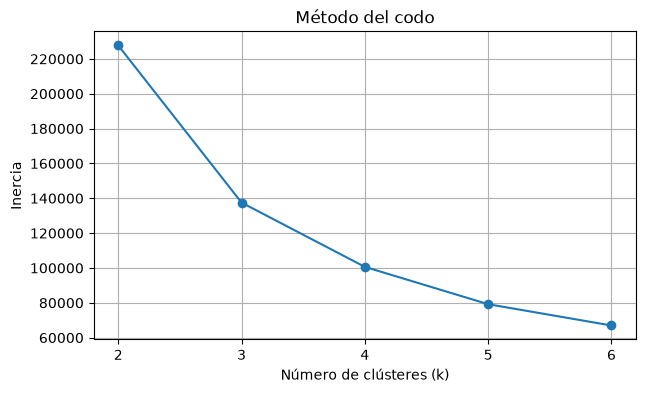

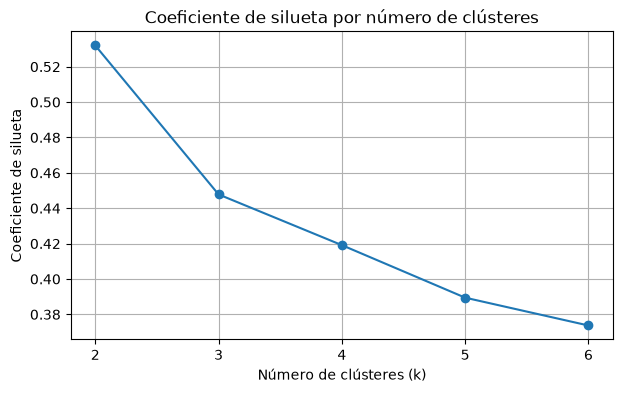

In [26]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

valores_k = [2, 3, 4, 5, 6]
resultados = []

for k in valores_k:
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    etiquetas = modelo.fit_predict(X_escalado)
    
    resultados.append({
        "k": k,
        "Inercia": modelo.inertia_,
        "Silueta": silhouette_score(
            X_escalado,
            etiquetas,
            sample_size=5000,
            random_state=42
        )
    })

# Tabla comparativa
tabla_resultados = pd.DataFrame(resultados)
display(tabla_resultados)

# Gráfica del método del codo
plt.figure(figsize=(7, 4))
plt.plot(tabla_resultados["k"], tabla_resultados["Inercia"], marker="o")
plt.title("Método del codo")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Inercia")
plt.xticks(valores_k)
plt.grid(True)
plt.show()

# Gráfica del coeficiente de silueta
plt.figure(figsize=(7, 4))
plt.plot(tabla_resultados["k"], tabla_resultados["Silueta"], marker="o")
plt.title("Coeficiente de silueta por número de clústeres")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Coeficiente de silueta")
plt.xticks(valores_k)
plt.grid(True)
plt.show()

## 6. Modelo final y visualización — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Elegir un valor de `k` a partir de los resultados anteriores.
2. Entrenar un modelo final `KMeans` con ese valor, `random_state=42` y `n_init=10`.
3. Obtener las etiquetas de clúster para cada viaje.
4. Generar una **gráfica de dispersión** usando las dos columnas de `X_escalado`: eje X = **`trip_distance`**, eje Y = **`trip_duration`**, ambas transformadas y estandarizadas.
5. Colorear los puntos según el clúster asignado.
6. Dibujar los **centroides** del modelo con marcadores **X** de tamaño visible y un color que contraste.
7. Agregar título, nombres de ejes y leyenda de centroides.

**Evidencia:** gráfica final con clústeres y centroides.

**Nota sobre la visualización:** la gráfica debe mostrar los datos y centroides **transformados y estandarizados**, tal como los utiliza K-Means. Los valores de sus ejes no representan directamente las unidades originales.

Valor de k seleccionado: 2


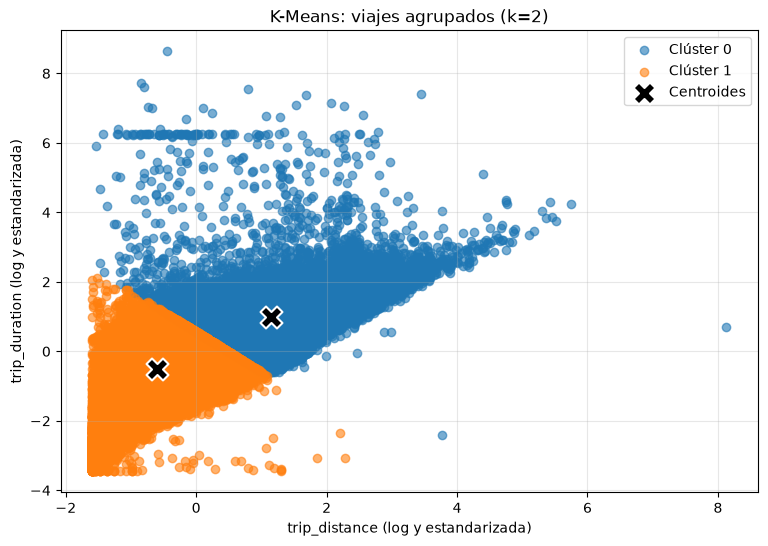

In [27]:
# Seleccionar k con mayor silueta entre los valores evaluados
k_final = int(
    tabla_resultados.loc[tabla_resultados["Silueta"].idxmax(), "k"]
)
print("Valor de k seleccionado:", k_final)

# Entrenar el modelo final con los datos estandarizados
modelo_final = KMeans(
    n_clusters=k_final,
    random_state=42,
    n_init=10
)

etiquetas = modelo_final.fit_predict(X_escalado)

# Guardar las etiquetas en los viajes originales para interpretar los grupos
df_cash["cluster"] = etiquetas

# Graficar los datos estandarizados y los centroides
plt.figure(figsize=(9, 6))

for cluster in range(k_final):
    puntos = X_escalado.loc[etiquetas == cluster]
    plt.scatter(
        puntos["trip_distance"],
        puntos["trip_duration"],
        label=f"Clúster {cluster}",
        alpha=0.6
    )

centroides = modelo_final.cluster_centers_
plt.scatter(
    centroides[:, 0],
    centroides[:, 1],
    marker="X",
    s=250,
    c="black",
    edgecolors="white",
    linewidths=1.5,
    label="Centroides"
)

plt.title(f"K-Means: viajes agrupados (k={k_final})")
plt.xlabel("trip_distance (log y estandarizada)")
plt.ylabel("trip_duration (log y estandarizada)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 7. Estadísticos de los clústeres y preguntas de análisis — 23 puntos · 15 minutos

**Parte A. Tabla de estadísticos — 11 puntos**

**Importante:** calcula los estadísticos descriptivos usando los **datos originales de las variables, sin aplicarles la transformación logarítmica ni la estandarización**. Usa las etiquetas del modelo para agrupar los registros, pero toma los valores de `df_cash`, no de `X_escalado`.

**Escribe el código necesario para:**
1. Crear un DataFrame llamado `df_resultado` a partir de `df_cash`.
2. Agregar una columna `cluster` con las etiquetas obtenidas en el modelo final.
3. Agrupar por `cluster` y calcular, para cada grupo:
   - **Cantidad de viajes**.
   - **Media y mediana** de `trip_distance`.
   - **Media y mediana** de `trip_duration`.
4. Mostrar la tabla con valores redondeados a dos decimales. Los resultados deben expresarse en sus **unidades originales**: millas para la distancia y minutos para la duración.

**Evidencia:** tabla de estadísticos por clúster.

In [28]:
# Crear el DataFrame de resultados y agregar las etiquetas del modelo final
df_resultado = df_cash.copy()
df_resultado["cluster"] = etiquetas

# Calcular estadísticos por clúster con las variables originales
tabla_clusters = (
    df_resultado
    .groupby("cluster")
    .agg(
        cantidad_viajes=("cluster", "size"),
        distancia_media=("trip_distance", "mean"),
        distancia_mediana=("trip_distance", "median"),
        duracion_media=("trip_duration", "mean"),
        duracion_mediana=("trip_duration", "median")
    )
    .round(2)
)

display(tabla_clusters)

,cantidad_viajes,distancia_media,distancia_mediana,duracion_media,duracion_mediana
cluster,,,,,
0,95794,8.82,7.06,33.04,25.85
1,186291,1.28,1.13,9.52,8.95


**Parte B. Preguntas de análisis — 12 puntos (3 puntos por pregunta).** Responde las cuatro preguntas con tus propias palabras. Usa las métricas, la gráfica y la tabla de estadísticos como evidencia. No basta con mencionar el número de clúster.

**Pregunta 1 — Selección de k.** ¿Qué valor de `k` elegiste y por qué? Justifica tu decisión utilizando **inercia, silueta** y, si corresponde, la claridad de los grupos obtenidos.

**Respuesta:** Elegí el 2, ya que en los calculos del coeficiente de silueta, fue el que mas cercas estaba del numero 1 esto indicando que los puntos estan muy bien agrupados y separados, ademas con el metodo del codo, me di cuenta que a partir del 2 y 3, las variaciones sobre el valor no eran tan significativas. Lo que demuestra que es de ayuda tener dos metodos de referencia para seleccionar el valor de k


**Pregunta 2 — Interpretación de grupos.** Describe las características de **cada clúster** a partir de la cantidad de viajes, las medias y las medianas. Asigna a cada grupo un nombre descriptivo.

**Respuesta:**  El cluster 0: Viajes largos: contiene 95,794 viajes. La distancia promedio fue de 8.82 millas y la mediana de 7.06 millas. La duración promedio fue de 33.04 minutos y la mediana de 25.85 minutos.

EL cluster 1: Viajes cortos: contiene 186,291 viajes. La distancia promedio fue de 1.28 millas y la mediana de 1.13 millas. La duración promedio fue de 9.52 minutos y la mediana de 8.95 minutos.


**Pregunta 3 — Análisis sencillo.** ¿Qué cluster presenta la mayor duración promedio? ¿Tambien tiene la mayor distancia promedio? Explica usando la tabla.

**Respuesta:** El clúster 0 tiene la mayor duración promedio, con 33.04 minutos. Tambien presenta la mayor distancia promedio, con 8.82 millas; ambas cifras superan las del cluster 1, que promedia 9.52 minutos y 1.28 millas.


**Pregunta 4 — Análisis sencillo.** ¿Cuál es el grupo más numeroso? ¿Qué características de distancia y duración predominan en ese grupo?

**Respuesta:** El clúster 1 es el más numeroso, con 186,291 viajes, frente a los 95,794 del clúster 0. En este grupo predominan los trayectos cortos y rápidos: la distancia mediana es 1.13 millas y la duración mediana es 8.95 minutos.

---
### Lista de verificación antes de entregar

- [ ] Se muestran la carga, exploración, limpieza y filtrado.
- [ ] Se utilizaron las **dos variables indicadas**.
- [ ] Se aplicaron `log1p` y `StandardScaler`.
- [ ] Se calcularon inercia y silueta para `k = 2...6`.
- [ ] Se muestran la tabla de métricas y las dos gráficas de evaluación.
- [ ] Se visualizan los clústeres y sus centroides.
- [ ] Se presenta la tabla de estadísticos calculados sobre los **datos originales**, sin transformación ni estandarización, en sus unidades correspondientes.
- [ ] Se respondieron las cuatro preguntas finales.

**Distribución de puntos (sobre 100):** carga y exploración: 7; limpieza: 14; filtrado y selección: 7; transformación y estandarización: 14; evaluación de k: 21; modelo y visualización: 14; estadísticos: 11; preguntas de análisis: 12. **Total: 100 puntos.**